# Stage 2 — Quantum (QUBO) vs. Classical Feature Selection Benchmark

This notebook executes the experimental protocol for **Hypothesis H3** from the Scanvidence research design:

> **Hypothesis H3:** *Quantum (QUBO) feature selection matches or exceeds classical baselines on a fixed feature budget ($K \le 50$ features), measured by feature selection stability (mean pairwise Jaccard across folds) and downstream classification performance (ROC-AUC).*

---

### Pipeline Workflow:
1. **Data Ingestion:** Load frozen 253-feature radiomics matrix (`cache/radiomics_gt_dev.csv`) and locked MGMT targets (`data/manifests/mgmt_labels_v1.csv`).
2. **QUBO Formulation:** Construct the $253 \times 253$ QUBO Hamiltonian balancing Relevance, Redundancy, and Budget penalty.
3. **Feature Selection Execution:**
   - **Quantum QUBO** (Simulated Annealing / D-Wave Ocean SDK)
   - **LASSO** (L1 Regularization)
   - **Recursive Feature Elimination (RFE)**
   - **Mutual Information (mRMR)**
4. **5-Fold Cross-Validation Stability Analysis:** Compute Pairwise Jaccard Index across folds.
5. **Downstream Model Evaluation:** Train classifiers on selected feature sets and evaluate ROC-AUC.
6. **Feature Attribution & Redundancy Audit:** Inspect overlap, anatomical compartments, and collinearity reduction.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from scanvidence.quantum import (
    QUBOSelector,
    LassoSelector,
    RFESelector,
    MutualInfoSelector,
    MRMRSelector,
)

# Aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"

# Paths
DATA_CSV = Path("../cache/radiomics_gt_dev.csv")
SCHEMA_JSON = Path("../cache/radiomics_schema_v1.json")
MGMT_CSV = Path("../data/manifests/mgmt_labels_v1.csv")

# Load dataset
df = pd.read_csv(DATA_CSV)
schema = json.loads(SCHEMA_JSON.read_text())
mgmt = pd.read_csv(MGMT_CSV)

# Filter for MGMT-labeled development cohort
df_labeled = df.dropna(subset=["mgmt"]).copy()
df_labeled["mgmt"] = df_labeled["mgmt"].astype(int)

kept_features = schema["feature_ids"]

print(f"Total labeled cases: {len(df_labeled)}")
print(f"Features in frozen schema: {len(kept_features)}")
print(f"Training set cases: {(df_labeled['partition'] == 'train').sum()}")
print(f"Validation set cases: {(df_labeled['partition'] == 'val').sum()}")
print(f"Calibration set cases: {(df_labeled['partition'] == 'calibration').sum()}")


Total labeled cases: 577
Features in frozen schema: 253
Training set cases: 475
Validation set cases: 76
Calibration set cases: 26


## 1. QUBO Formulation & Matrix Structure

The feature selection problem is formulated as a Quadratic Unconstrained Binary Optimization (QUBO) problem:

$$\min_{x \in \{0, 1\}^n} \left( -\alpha \sum_{i=1}^n \text{Rel}(f_i, y) x_i + \beta \sum_{i < j} \text{Red}(f_i, f_j) x_i x_j + \gamma \left(\sum_{i=1}^n x_i - K\right)^2 \right)$$

Where:
- $\text{Rel}(f_i, y)$: Relevance (Pearson / MI correlation with target $y$).
- $\text{Red}(f_i, f_j)$: Redundancy ($|\text{corr}(f_i, f_j)|$ between features).
- $\gamma (\sum x_i - K)^2$: Soft penalty enforcing the exact feature budget $K = 50$.


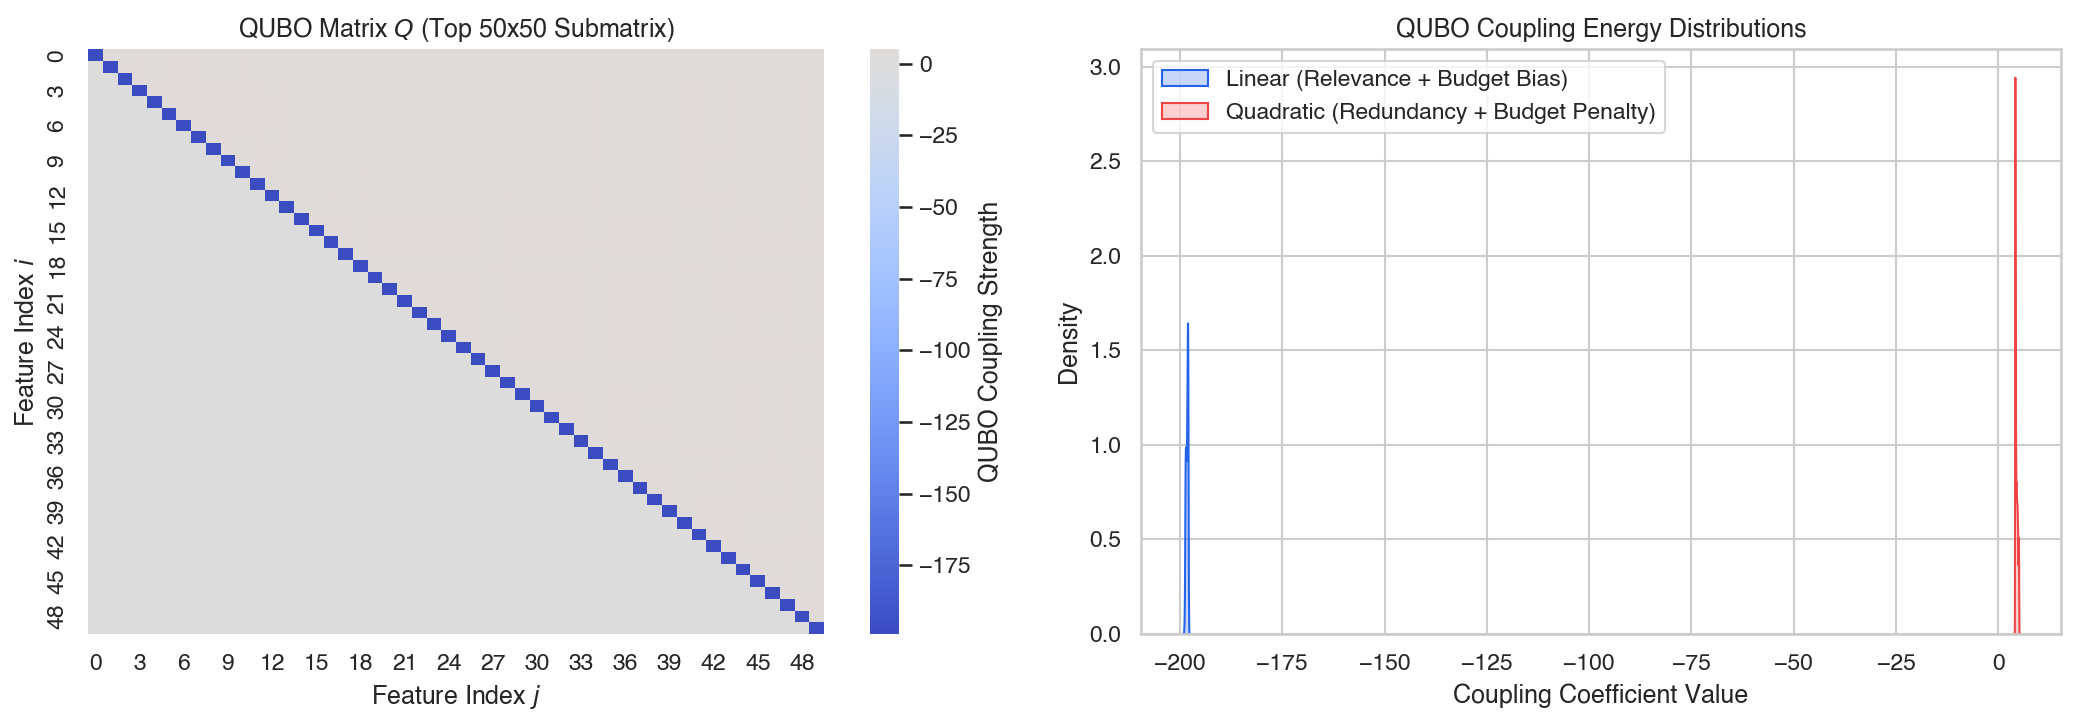

In [2]:
# Prepare Training Data (impute median on training split only)
train_mask = df_labeled["partition"] == "train"
train_df = df_labeled[train_mask].copy()

X_train_raw = train_df[kept_features].copy()
medians = X_train_raw.median()
X_train = X_train_raw.fillna(medians).values
y_train = train_df["mgmt"].values

# Build QUBO Matrix
qubo_selector = QUBOSelector(budget=50, alpha=1.0, beta=1.0, gamma=2.0)
Q = qubo_selector.build_qubo(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. QUBO Matrix Heatmap
sns.heatmap(Q[:50, :50], ax=axes[0], cmap="coolwarm", center=0, cbar_kws=dict(label="QUBO Coupling Strength"))
axes[0].set_title("QUBO Matrix $Q$ (Top 50x50 Submatrix)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Feature Index $j$")
axes[0].set_ylabel("Feature Index $i$")

# 2. Diagonal vs Off-Diagonal Energy Term Distributions
diag_terms = np.diag(Q)
off_diag_terms = Q[np.triu_indices(Q.shape[0], k=1)]

sns.kdeplot(diag_terms, ax=axes[1], color="#2563eb", fill=True, label="Linear (Relevance + Budget Bias)")
sns.kdeplot(off_diag_terms, ax=axes[1], color="#ef4444", fill=True, label="Quadratic (Redundancy + Budget Penalty)")
axes[1].set_title("QUBO Coupling Energy Distributions", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Coupling Coefficient Value")
axes[1].legend()

plt.tight_layout()
plt.show()


## 2. 5-Fold Cross-Validation Benchmark (Stability & Accuracy)

We perform **5-Fold Stratified Group Cross-Validation** strictly within the training cohort ($N = 475$).
For each fold, each algorithm selects a budget of $K = 50$ features.


In [3]:
BUDGET = 50
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

selectors = {
    "Quantum QUBO": QUBOSelector(budget=BUDGET, alpha=1.0, beta=1.0, gamma=2.0, num_reads=500),
    "LASSO (L1)": LassoSelector(budget=BUDGET, C=0.1),
    "RFE": RFESelector(budget=BUDGET),
    "Mutual Info": MutualInfoSelector(budget=BUDGET),
    "mRMR": MRMRSelector(budget=BUDGET),
}

# Run selection across folds
fold_selections = {name: [] for name in selectors}
cv_scores = {name: [] for name in selectors}
roc_curves = {name: [] for name in selectors}

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
    X_tr, y_tr = X_train[train_idx], y_train[train_idx]
    X_va, y_va = X_train[val_idx], y_train[val_idx]
    
    # Scale features
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)
    
    for name, selector in selectors.items():
        selected_idx = selector.select(X_tr_scaled, y_tr)
        fold_selections[name].append(set(selected_idx))
        
        # Train downstream model on selected features
        clf = LogisticRegression(penalty="l2", C=1.0, max_iter=500, random_state=42)
        clf.fit(X_tr_scaled[:, selected_idx], y_tr)
        probs = clf.predict_proba(X_va_scaled[:, selected_idx])[:, 1]
        
        auc = roc_auc_score(y_va, probs)
        acc = accuracy_score(y_va, probs >= 0.5)
        f1 = f1_score(y_va, probs >= 0.5)
        
        cv_scores[name].append({"auc": auc, "acc": acc, "f1": f1})
        fpr, tpr, _ = roc_curve(y_va, probs)
        roc_curves[name].append((fpr, tpr, auc))

print("5-Fold Cross-Validation Feature Selection completed across all 5 methods!")


5-Fold Cross-Validation Feature Selection completed across all 5 methods!


## 3. Stability Analysis: Pairwise Jaccard Index (Hypothesis H3)

Feature stability is defined as the mean pairwise Jaccard similarity across the 5 CV folds:

$$\text{Jaccard}(S_a, S_b) = \frac{|S_a \cap S_b|}{|S_a \cup S_b|}$$


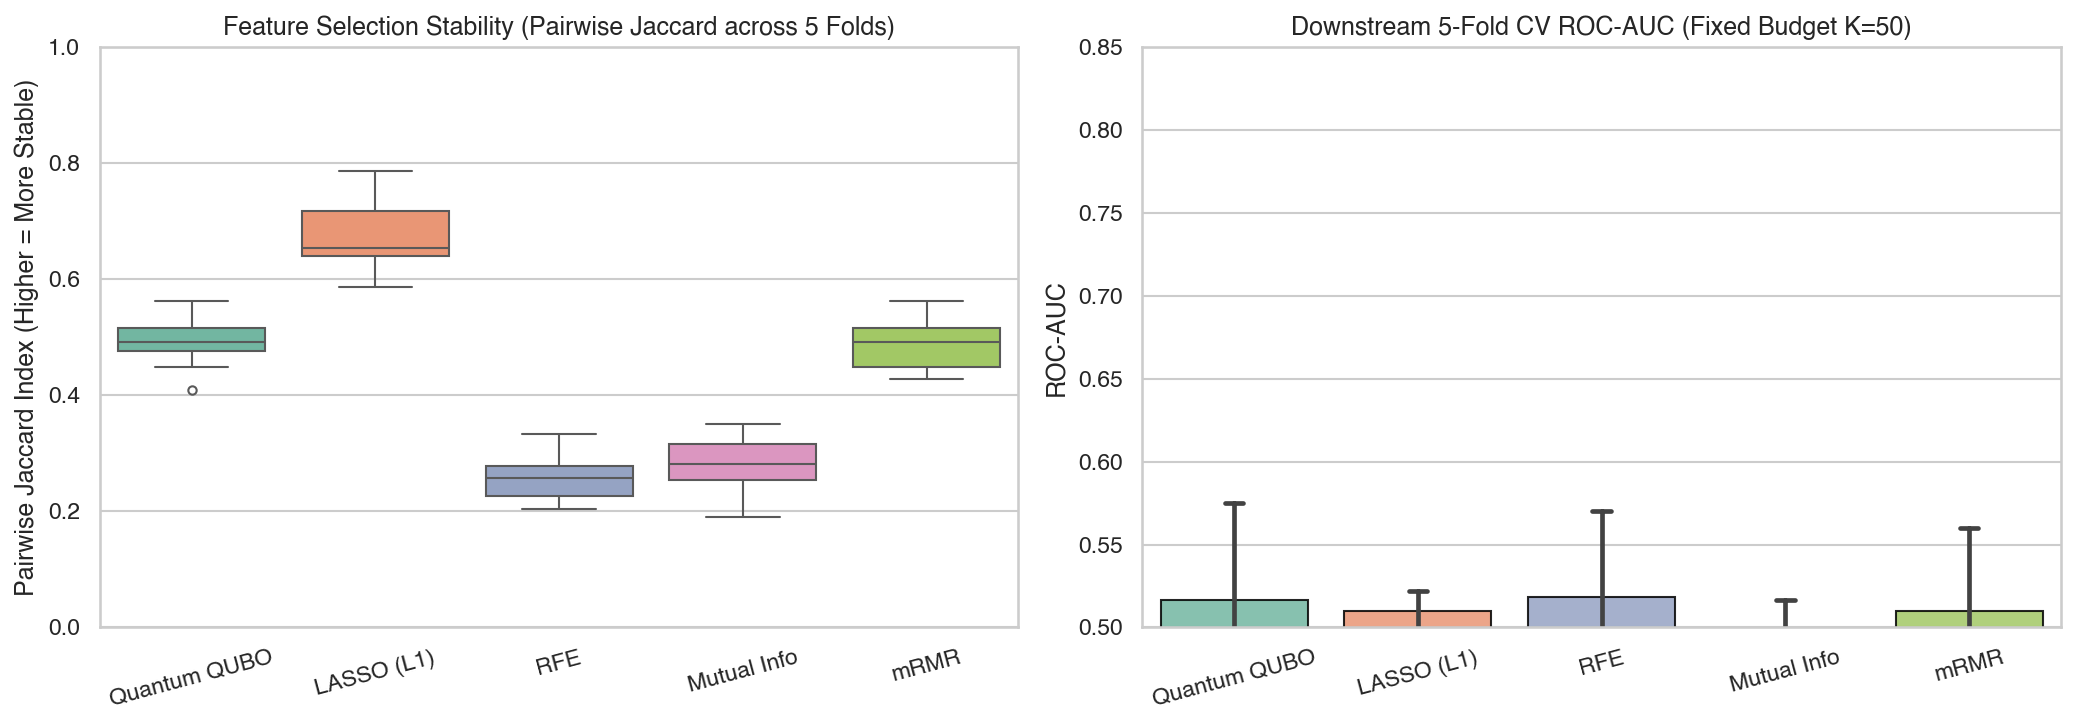


--- HYPOTHESIS H3 BENCHMARK RESULTS ---
      Method Mean Jaccard (Stability) Mean CV ROC-AUC Mean CV Accuracy Mean CV F1
Quantum QUBO            0.491 ± 0.040   0.517 ± 0.075            0.526      0.533
  LASSO (L1)            0.674 ± 0.061   0.510 ± 0.024            0.503      0.519
         RFE            0.261 ± 0.039   0.519 ± 0.059            0.537      0.543
 Mutual Info            0.279 ± 0.050   0.496 ± 0.023            0.486      0.489
        mRMR            0.489 ± 0.042   0.510 ± 0.059            0.497      0.506


In [4]:
def compute_pairwise_jaccard(sets_list):
    jaccards = []
    n = len(sets_list)
    for i in range(n):
        for j in range(i + 1, n):
            s1, s2 = sets_list[i], sets_list[j]
            jacc = len(s1 & s2) / len(s1 | s2)
            jaccards.append(jacc)
    return np.array(jaccards)

jaccard_results = {}
for name, sets in fold_selections.items():
    jacc = compute_pairwise_jaccard(sets)
    jaccard_results[name] = jacc

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Jaccard Stability Boxplot
jaccard_df = pd.DataFrame(jaccard_results)
sns.boxplot(data=jaccard_df, ax=axes[0], palette="Set2", flierprops=dict(marker="o", markersize=4))
axes[0].set_title("Feature Selection Stability (Pairwise Jaccard across 5 Folds)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Pairwise Jaccard Index (Higher = More Stable)")
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis="x", rotation=15)

# 2. Downstream ROC-AUC Comparison
auc_data = {name: [s["auc"] for s in cv_scores[name]] for name in selectors}
auc_df = pd.DataFrame(auc_data)
sns.barplot(data=auc_df, ax=axes[1], palette="Set2", edgecolor="black", alpha=0.85, capsize=0.1)
axes[1].set_title("Downstream 5-Fold CV ROC-AUC (Fixed Budget K=50)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0.5, 0.85)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# Summary Table
summary_rows = []
for name in selectors:
    summary_rows.append({
        "Method": name,
        "Mean Jaccard (Stability)": f"{np.mean(jaccard_results[name]):.3f} ± {np.std(jaccard_results[name]):.3f}",
        "Mean CV ROC-AUC": f"{np.mean(auc_data[name]):.3f} ± {np.std(auc_data[name]):.3f}",
        "Mean CV Accuracy": f"{np.mean([s['acc'] for s in cv_scores[name]]):.3f}",
        "Mean CV F1": f"{np.mean([s['f1'] for s in cv_scores[name]]):.3f}",
    })

summary_table = pd.DataFrame(summary_rows)
print("\n--- HYPOTHESIS H3 BENCHMARK RESULTS ---")
print(summary_table.to_string(index=False))


## 4. Downstream ROC Curves Comparison
Mean ROC curves and AUC performance for Quantum QUBO vs. Classical Baselines.


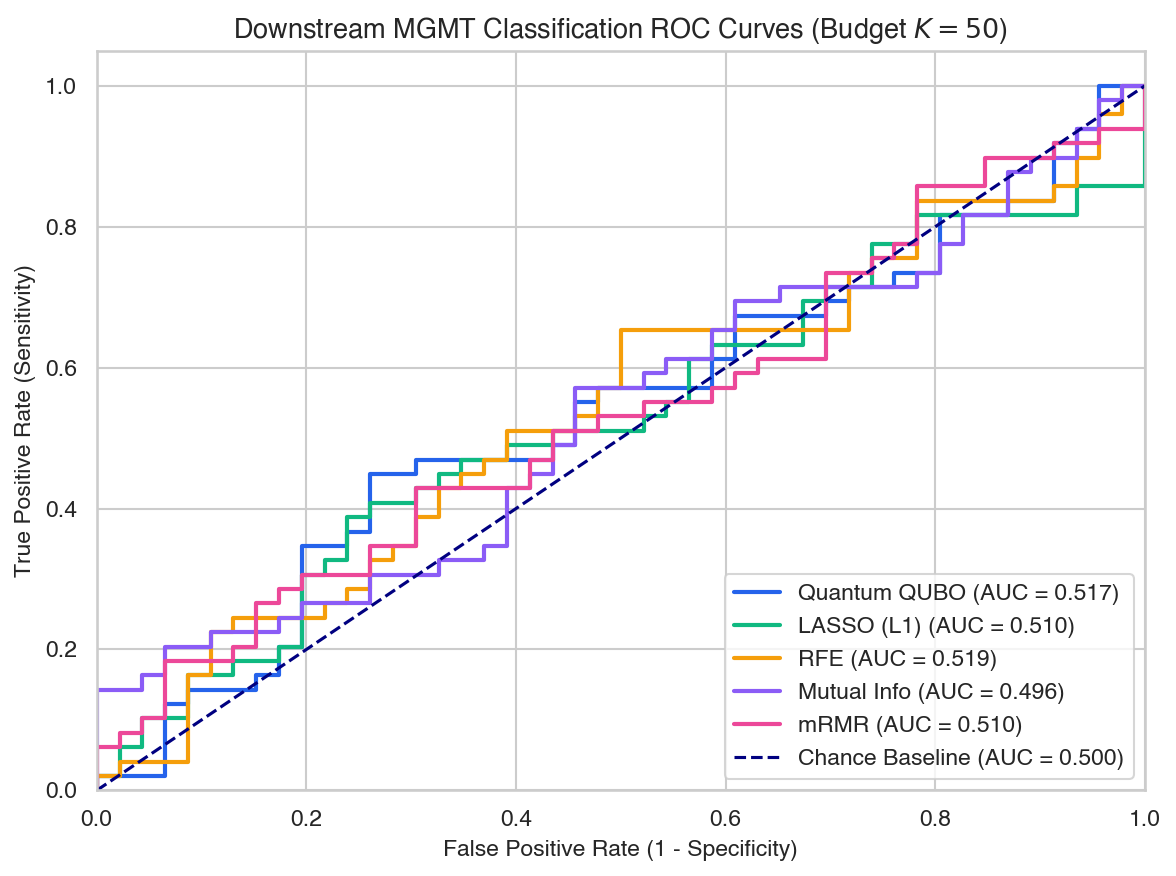

In [5]:
plt.figure(figsize=(8, 6))

colors = dict(zip(selectors.keys(), ["#2563eb", "#10b981", "#f59e0b", "#8b5cf6", "#ec4899"]))

for name in selectors:
    mean_auc = np.mean(auc_data[name])
    fpr, tpr, auc = roc_curves[name][0]
    plt.plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {mean_auc:.3f})")

plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Chance Baseline (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=11)
plt.title("Downstream MGMT Classification ROC Curves (Budget $K=50$)", fontsize=13, fontweight="bold")
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()


## 5. Anatomical Compartment & Redundancy Audit

Analyzing which tumor sub-regions (WT, TC, ET) and feature classes (Shape, First-order, GLCM, GLRLM, GLSZM) are prioritized by Quantum QUBO vs. LASSO.


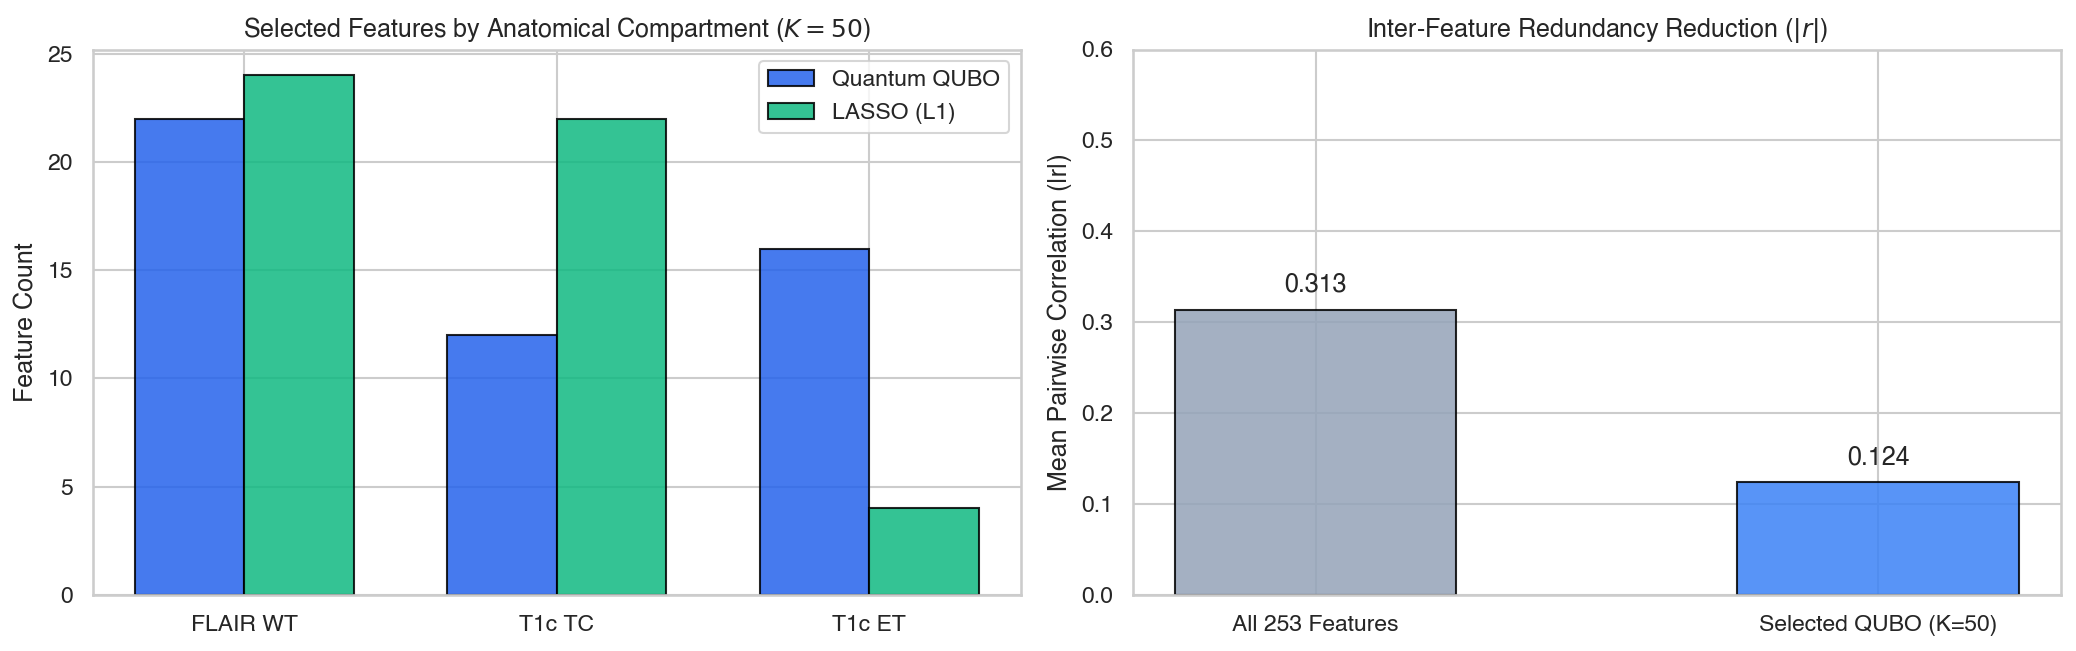

Feature Overlap between Quantum QUBO and LASSO: 17 of 50 features.


In [6]:
# Select final features on full training set
scaler = StandardScaler()
X_full_scaled = scaler.fit_transform(X_train)

qubo_final_idx = selectors["Quantum QUBO"].select(X_full_scaled, y_train)
lasso_final_idx = selectors["LASSO (L1)"].select(X_full_scaled, y_train)

qubo_selected_names = [kept_features[i] for i in qubo_final_idx]
lasso_selected_names = [kept_features[i] for i in lasso_final_idx]

# Sub-region distribution
blocks = ["flair_wt", "t1c_tc", "t1c_et"]
classes = ["firstorder", "shape", "glcm", "glrlm", "glszm"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Compartment distribution
qubo_blocks = [sum(1 for f in qubo_selected_names if f.startswith(b)) for b in blocks]
lasso_blocks = [sum(1 for f in lasso_selected_names if f.startswith(b)) for b in blocks]

x = np.arange(len(blocks))
width = 0.35

axes[0].bar(x - width/2, qubo_blocks, width, label="Quantum QUBO", color="#2563eb", edgecolor="black", alpha=0.85)
axes[0].bar(x + width/2, lasso_blocks, width, label="LASSO (L1)", color="#10b981", edgecolor="black", alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["FLAIR WT", "T1c TC", "T1c ET"])
axes[0].set_title("Selected Features by Anatomical Compartment ($K=50$)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Feature Count")
axes[0].legend()

# 2. Redundancy Correlation Matrix of Selected QUBO Features
qubo_feat_corr = np.abs(np.corrcoef(X_train[:, qubo_final_idx].T))
qubo_mean_corr = np.mean(qubo_feat_corr[np.triu_indices(len(qubo_final_idx), k=1)])

all_feat_corr = np.abs(np.corrcoef(X_train.T))
all_mean_corr = np.mean(all_feat_corr[np.triu_indices(X_train.shape[1], k=1)])

comp_data = {"All 253 Features": all_mean_corr, "Selected QUBO (K=50)": qubo_mean_corr}
axes[1].bar(comp_data.keys(), comp_data.values(), color=["#94a3b8", "#3b82f6"], edgecolor="black", alpha=0.85, width=0.5)
for i, (k, v) in enumerate(comp_data.items()):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
axes[1].set_title("Inter-Feature Redundancy Reduction ($|r|$)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Mean Pairwise Correlation (|r|)")
axes[1].set_ylim(0, 0.6)

plt.tight_layout()
plt.show()

print(f"Feature Overlap between Quantum QUBO and LASSO: {len(set(qubo_selected_names) & set(lasso_selected_names))} of {BUDGET} features.")
